# 5. The two-stage market: constraint costs in 2030

Great Britain's electricity market sets one national price, as if power could flow anywhere. The real network cannot
carry everything that market schedules, so NESO then pays some generators to turn down and others to turn up: the
balancing mechanism. What that costs is the constraint cost, and NESO expects it to grow sharply by 2030 as offshore
wind arrives faster than the network that carries it south.

PyPSA-GB models the two steps in turn. This tutorial runs one week, 10 to 16 February 2030, of the
[Clean Power 2030 study](../studies/cp30_2030.md): NESO's Clean Power 2030 (CP30) pathway, on the full network, with
two transmission projects (Norwich-Tilbury and Sea Link) not yet built, the study's CENTRAL case.

You will see:

- the wholesale market (Stage 1): dispatch and price with no network limits;
- the balancing mechanism (Stage 2): what has to move when the network is applied, and what it costs;
- where wind is turned down, and how interconnector trades are reversed.

This is the largest tutorial: about 20 minutes to build the 2030 network the first time, and 20 more to solve the
week, on a machine with 16 GB of memory or more.

## The scenario

The week is defined in the CP30 study (`config/studies/cp30_2030/scenarios.yaml`), from the same building blocks as
the study's month-long runs:

```yaml
CP30_FFR_2030_tutorial_week:
  description: 'Tutorials: CP30 FFR 2030, 10-16 February, wholesale market and balancing mechanism on the CENTRAL network'
  inherits: [cp30_ffr_2030_month, market_balancing, network_no_acceleration]
  solve_period:
    enabled: true
    start: 2030-02-10 00:00
    end: 2030-02-16 23:00
```

- `cp30_ffr_2030_month` solves on the study's full-year 2030 network, `CP30_FFR_2030`: the CP30 fleet placed site by
  site on the full ETYS network, with 2013 weather, the year CP30 itself uses.
- `market_balancing` turns on the two stages, with the study's bids and offers: a gas plant offers to turn up at 1.6
  times its fuel and carbon cost; a wind farm on a Contract for Difference asks to be paid the support it loses by
  turning down; a cross-border trade is reversed at its value abroad plus GBP 20/MWh.
- `network_no_acceleration` removes Norwich-Tilbury and Sea Link from the balancing stage's network.

The model description has each stage in full ([wholesale](../model/dispatch/wholesale.md),
[balancing](../model/dispatch/balancing.md), [bids and offers](../model/dispatch/bids_offers_support.md)).

## Run it

1. `config/config.yaml` must load the CP30 study (it does by default):

   ```yaml
   studies:
     - cp30_2030
   ```

2. Run the week:

   ```bash
   snakemake -j 4 --config scenario=CP30_FFR_2030_tutorial_week
   ```

   The first time, Snakemake downloads NESO's CP30 data workbook and builds the 2030 network; you also need the 2013
   weather data and a Gurobi licence (the full network is slow with HiGHS).

3. The two stages are written to `resources/market/`: `CP30_FFR_2030_tutorial_week_wholesale.nc` (Stage 1) and
   `_balancing.nc` (Stage 2), with tables of prices, redispatch and costs beside them, and a summary in
   `resources/analysis/CP30_FFR_2030_tutorial_week_market_summary.json`.

In [1]:
from pathlib import Path
import logging
import os
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import pypsa

logging.getLogger("pypsa").setLevel(logging.ERROR)  # keep the notebook output short
warnings.filterwarnings("ignore", message=".*GDAL.*")
warnings.filterwarnings("ignore", message=".*gdalvrt.*")

# Work from the repository root, wherever Jupyter was started.
ROOT = Path.cwd()
while not (ROOT / "Snakefile").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)

# Technology groups for charts: each PyPSA-GB carrier belongs to one group.
GROUPS = {
    "Nuclear": ["nuclear"],
    "Coal": ["coal"],
    "Gas": ["CCGT", "OCGT", "gas_engine", "CHP", "CCS Gas"],
    "Oil": ["oil"],
    "Bioenergy": ["biomass", "CCS Biomass", "biogas", "landfill_gas", "sewage_gas", "waste_to_energy",
                  "advanced_biofuel", "geothermal"],
    "Hydro": ["large_hydro", "small_hydro"],
    "Marine": ["marine", "tidal_stream", "shoreline_wave", "tidal_lagoon"],
    "Onshore wind": ["wind_onshore", "embedded_wind"],
    "Offshore wind": ["wind_offshore", "floating_wind"],
    "Solar": ["solar_pv", "embedded_solar"],
}
GROUP_OF = {carrier: group for group, carriers in GROUPS.items() for carrier in carriers}
COLOURS = {
    "Nuclear": "#6250d6", "Coal": "#4b4b4b", "Gas": "#eb6834", "Oil": "#9b6a4f", "Bioenergy": "#008300",
    "Hydro": "#5fa8d3", "Marine": "#1f9e9e", "Onshore wind": "#1baf7a", "Offshore wind": "#2a78d6",
    "Solar": "#eda100", "Hydrogen": "#e34948", "Storage": "#e87ba4", "Imports": "#9aa5a0",
}
# Consumer flexibility (EVs, heat, demand response) is built from storage units but counts as demand.
CONSUMER_FLEX = {"EV_smart_charging", "V2G_fleet", "HP_flexibility", "DH_flexibility", "SH_flexibility",
                 "IC_DSR", "residential_DSR", "DACCS"}

plt.rcParams.update({"figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e9e7", "legend.frameon": False, "font.size": 10})


def load(path):
    """Open a solved network, or say how to make it."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{path} does not exist yet: run the scenario first (see 'Run it' above).")
    return pypsa.Network(path)


def series(n, component, attribute, names):
    """A time series for each named component; a component without one takes its static value (or zero)."""
    table = getattr(n, f"{component}_t")[attribute]
    static = getattr(n, component).get(attribute, pd.Series(0.0, index=getattr(n, component).index))
    out = table.reindex(columns=names)
    for name in out.columns[out.isna().all()]:
        out[name] = float(static.get(name, 0.0)) if attribute in ("p_set", "p_max_pu") else 0.0
    return out.fillna(0.0)


def link_output(n, names):
    """Power each link delivers at its bus1 end (MW): p0 times efficiency, so it works whether or not p1 was saved."""
    return series(n, "links", "p0", names) * n.links.efficiency.reindex(names).values


def gb_buses(n):
    """GB electricity buses (the hydrogen bus is left out)."""
    return n.buses.index[(n.buses.country == "GB") & (n.buses.carrier == "AC")]


def generation_by_group(n):
    """GB generation by technology group (MW per snapshot); hydrogen turbines are their own group."""
    gens = n.generators[n.generators.bus.isin(gb_buses(n)) & n.generators.carrier.isin(GROUP_OF)]
    out = series(n, "generators", "p", gens.index).T.groupby(gens.carrier.map(GROUP_OF)).sum().T
    turbines = n.links.index[n.links.carrier == "H2_turbine"]
    if len(turbines):
        out["Hydrogen"] = link_output(n, turbines).sum(axis=1)  # output at the electricity end
    return out[[g for g in COLOURS if g in out and out[g].abs().sum() > 0]]


def interconnectors(n):
    cc = n.links.get("counterparty_country", pd.Series("", index=n.links.index)).fillna("").astype(str)
    return n.links[(n.links.carrier == "DC") & ~cc.isin(["", "nan", "None"])]


def net_imports(n):
    """Power the interconnectors deliver into GB (MW; negative = export)."""
    ic = interconnectors(n)
    gb = set(gb_buses(n))
    flows = {}
    for name, link in ic.iterrows():
        # p0 and p1 are withdrawals at bus0 and bus1; the GB end receives minus its withdrawal.
        # Power into GB: at bus0 it is minus the flow out of bus0; at bus1 it is the link's output there.
        flows[name] = (-series(n, "links", "p0", [name])[name] if link.bus0 in gb
                       else link_output(n, [name])[name])
    return pd.DataFrame(flows, index=n.snapshots).sum(axis=1)


def grid_storage(n):
    """Net output of grid storage (MW; positive = discharging). Consumer flexibility is left out."""
    units = n.storage_units.index[~n.storage_units.carrier.isin(CONSUMER_FLEX)]
    return series(n, "storage_units", "p", units).sum(axis=1)


def gb_demand(n):
    """GB electricity demand (MW): loads, the net draw of consumer flexibility, and electrolysis."""
    loads = n.loads.index[n.loads.bus.isin(gb_buses(n))]
    demand = series(n, "loads", "p_set", loads).sum(axis=1)
    flex = n.storage_units.index[n.storage_units.carrier.isin(CONSUMER_FLEX)]
    if len(flex):
        demand = demand - series(n, "storage_units", "p", flex).sum(axis=1)
    electrolysers = n.links.index[n.links.carrier == "electrolysis"]
    if len(electrolysers):
        demand = demand + series(n, "links", "p0", electrolysers).sum(axis=1)
    return demand


def day_axis(ax):
    """Label a time axis by day: Mon 10 Feb."""
    import matplotlib.dates as mdates
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))


def stack_plot(ax, supply, demand=None, title=None):
    """Stacked supply (GW) by group, positive above zero and negative (charging, exports) below."""
    gw = supply / 1e3
    pos, neg = gw.clip(lower=0), gw.clip(upper=0)
    ax.stackplot(gw.index, pos.T.values, colors=[COLOURS[c] for c in gw.columns], labels=gw.columns, lw=0)
    ax.stackplot(gw.index, neg.T.values, colors=[COLOURS[c] for c in gw.columns], lw=0)
    if demand is not None:
        ax.plot(demand.index, demand / 1e3, color="black", lw=1.4, label="Demand")
    ax.axhline(0, color="#555", lw=0.6)
    ax.set_ylabel("GW")
    day_axis(ax)
    if title:
        ax.set_title(title, loc="left")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))


import geopandas as gpd
from matplotlib.collections import LineCollection

GB_OUTLINE = gpd.read_file("data/network/GSP/GSP_regions_27700_20250109.geojson").to_crs(27700).dissolve()


def network_map(ax, n, line_values=None, cmap="viridis", vmin=0, vmax=1, bus_size=6, title=None):
    """GB buses and AC lines on British National Grid coordinates (metres); lines coloured by line_values."""
    GB_OUTLINE.plot(ax=ax, color="#eef3f0", edgecolor="#c9d6cf", lw=0.4)
    buses = n.buses.loc[gb_buses(n)]
    lines = n.lines[n.lines.bus0.isin(buses.index) & n.lines.bus1.isin(buses.index)]
    segments = [[(buses.x[a], buses.y[a]), (buses.x[b], buses.y[b])] for a, b in zip(lines.bus0, lines.bus1)]
    internal = n.links[n.links.carrier.isin(["DC", "AC"]) & n.links.bus0.isin(buses.index)
                       & n.links.bus1.isin(buses.index)]
    ax.add_collection(LineCollection(
        [[(buses.x[a], buses.y[a]), (buses.x[b], buses.y[b])] for a, b in zip(internal.bus0, internal.bus1)],
        colors="#7a8f86", linewidths=0.9, linestyles="dashed"))  # links inside GB (HVDC; zonal transport links)
    if line_values is None:
        collection = LineCollection(segments, colors="#7a8f86", linewidths=0.8)
    else:
        collection = LineCollection(segments, array=line_values.reindex(lines.index).values, cmap=cmap,
                                    linewidths=1.6, norm=plt.Normalize(vmin, vmax))
    ax.add_collection(collection)
    ax.scatter(buses.x, buses.y, s=bus_size, color="#2f4f43", zorder=3)
    ax.set_xlim(-20_000, 680_000)
    ax.set_ylim(-10_000, 1_225_000)
    ax.set_aspect("equal")
    ax.set_axis_off()
    if title:
        ax.set_title(title, loc="left")
    return collection

import json

SCENARIO = "CP30_FFR_2030_tutorial_week"
s1 = load(f"resources/market/{SCENARIO}_wholesale.nc")     # Stage 1: the wholesale market
bm = load(f"resources/market/{SCENARIO}_balancing.nc")     # Stage 2: the balancing mechanism
price = pd.read_csv(f"resources/market/{SCENARIO}_wholesale_price.csv", index_col=0, parse_dates=True)
summary = json.loads(Path(f"resources/analysis/{SCENARIO}_market_summary.json").read_text())
print(f"{len(bm.buses)} buses, {len(bm.lines)} lines, {len(bm.generators)} generators, {len(bm.snapshots)} hours")

2441 buses, 1933 lines, 12330 generators, 168 hours


## Stage 1: the wholesale market

Stage 1 schedules every generator, storage unit and interconnector at least cost, with GB treated as a single point.
This is the market's view of the week, and it sets the national wholesale price.

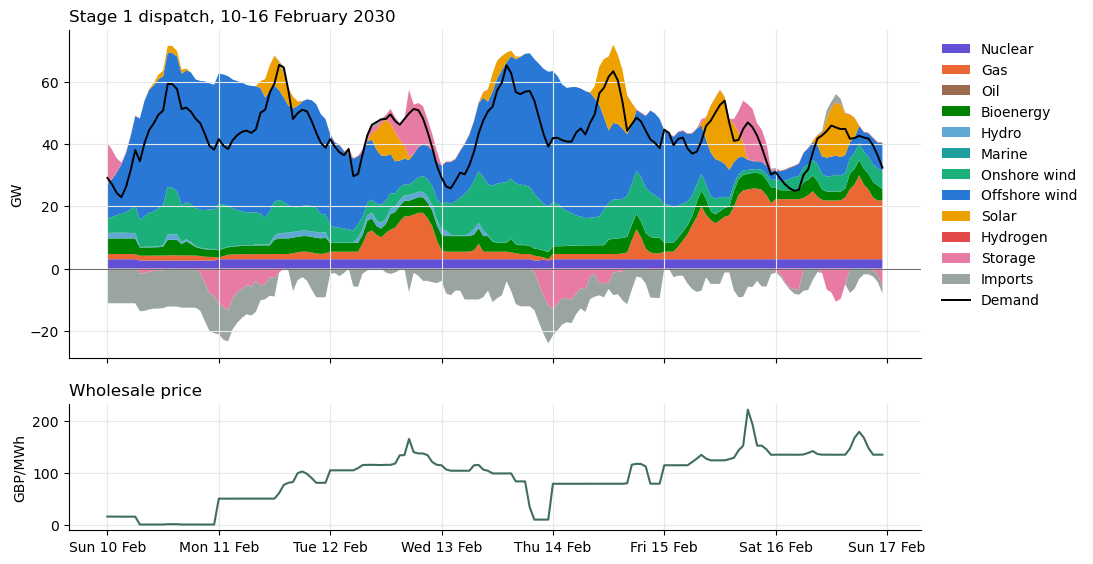

Mean wholesale price 91.0 GBP/MWh; 7% of hours at or near zero


,GWh over the week
carrier,
Nuclear,496.0
Gas,1215.0
Oil,0.0
Bioenergy,647.0
Hydro,83.0
Marine,11.0
Onshore wind,1503.0
Offshore wind,3991.0
Solar,526.0


In [2]:
supply = generation_by_group(s1)
supply["Storage"] = grid_storage(s1)
supply["Imports"] = net_imports(s1)

fig, (ax, axp) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, height_ratios=[2.6, 1])
stack_plot(ax, supply, gb_demand(s1), title="Stage 1 dispatch, 10-16 February 2030")
axp.plot(price.index, price.wholesale_price, color="#3f6f59", lw=1.5)
axp.set_ylabel("GBP/MWh")
axp.set_title("Wholesale price", loc="left")
plt.show()

print(f"Mean wholesale price {price.wholesale_price.mean():.1f} GBP/MWh; "
      f"{(price.wholesale_price <= 0.5).mean():.0%} of hours at or near zero")
(supply.sum() / 1e3).round(0).to_frame("GWh over the week")

Offshore wind dominates the week. On the windy Sunday and Monday GB exports up to 12 GW and the price falls to zero.
As the wind eases, gas comes in and the price climbs, to GBP 100-220/MWh by Saturday. The week's mean price, GBP 91/MWh,
is high for CP30 (the study's year averages GBP 55/MWh) because this is a winter week with calm days at its end.

## Stage 2: the balancing mechanism

Stage 2 starts from every unit's Stage 1 schedule and applies the real network: about 2,000 buses, each line's rating
and NESO's secured limits on the main boundaries. Where the schedule cannot flow, units are moved off it at the least
cost: plant behind a congested boundary is turned down (it bids), plant on the other side is turned up (it offers),
and interconnector trades are re-traded. The chart shows what moved, technology by technology.

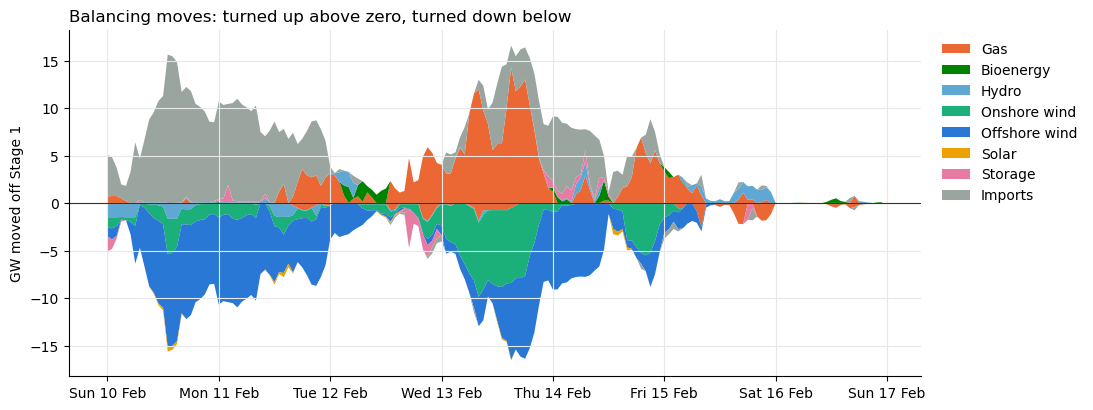

,"turned up, GWh","turned down, GWh"
carrier,,
Gas,326.9,38.1
Bioenergy,19.4,0.9
Hydro,30.9,30.9
Onshore wind,0.0,256.7
Offshore wind,0.0,588.0
Solar,0.0,6.2
Storage,14.9,16.3
Imports,552.8,7.8


In [3]:
def moves(s1, bm):
    gens = bm.generators[bm.generators.bus.isin(gb_buses(bm)) & bm.generators.carrier.isin(GROUP_OF)]
    delta = series(bm, "generators", "p", gens.index) - series(s1, "generators", "p", gens.index)
    group = gens.carrier.map(GROUP_OF)
    up = delta.clip(lower=0).T.groupby(group).sum().T
    down = -(-delta.clip(upper=0)).T.groupby(group).sum().T
    d_store = grid_storage(bm) - grid_storage(s1)
    d_ic = net_imports(bm) - net_imports(s1)
    up["Storage"], down["Storage"] = d_store.clip(lower=0), d_store.clip(upper=0)
    up["Imports"], down["Imports"] = d_ic.clip(lower=0), d_ic.clip(upper=0)
    order = [g for g in COLOURS if g in up and (up[g].abs().max() > 1 or down[g].abs().max() > 1)]
    return up[order], down[order]


up, down = moves(s1, bm)
fig, ax = plt.subplots(figsize=(11, 4.5))
colours = [COLOURS[c] for c in up.columns]
ax.stackplot(up.index, (up / 1e3).T.values, colors=colours, labels=up.columns, lw=0)
ax.stackplot(down.index, (down / 1e3).T.values, colors=colours, lw=0)
day_axis(ax)
ax.axhline(0, color="#333", lw=0.8)
ax.set_ylabel("GW moved off Stage 1")
ax.set_title("Balancing moves: turned up above zero, turned down below", loc="left")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.show()

pd.DataFrame({"turned up, GWh": up.sum() / 1e3, "turned down, GWh": -down.sum() / 1e3}).round(1)

In almost every hour, wind behind the network's bottlenecks is turned down (blue and green, below zero) and replaced
by gas and imports elsewhere (above zero). Over the week the balancing mechanism turns down 845 GWh of wind, about 15%
of what the market dispatched. "Imports turned up" is mostly exports cut back: GB cannot deliver to the coast all the
wind it sold abroad in Stage 1.

## What it cost

The constraint cost is what the balancing mechanism pays: accepted offers (plant turned up) plus accepted bids (plant
turned down) plus the cost of re-trading interconnectors. It is measured the way NESO measures its thermal constraint
cost, and kept apart from two things the model also reports: unserved energy, a last resort priced at the value of
lost load, and small units outside the balancing mechanism that had to be turned down at a penalty price.

In [4]:
acc = summary["accounting"]
cost = pd.Series({
    "Plant turned up (offers)": acc["accepted_offer_cost_GBP"],
    "Plant turned down (bids)": acc["accepted_bid_cost_GBP"],
    "Interconnector trades re-traded": acc["interconnector_retrading_cost_GBP"],
}) / 1e6
cost["Constraint cost"] = acc["neso_comparable_redispatch_cost_GBP"] / 1e6
print(f"Unserved energy: {acc['feasibility_slack_energy_MWh']:.1f} MWh; "
      f"energy moved in balancing: {acc['gb_gross_redispatch_MWh'] / acc['gb_electricity_demand_MWh']:.0%} of demand")

by_carrier = pd.read_csv(f"resources/market/{SCENARIO}_constraint_costs.csv", index_col=0)
by_carrier = (by_carrier.drop(index="TOTAL", errors="ignore")[["offer_cost", "bid_cost", "net_cost"]] / 1e6)
display(cost.round(1).to_frame("GBP m, this week"))
by_carrier.sort_values("net_cost", ascending=False).head(8).round(1)

Unserved energy: 0.1 MWh; energy moved in balancing: 18% of demand


,"GBP m, this week"
Plant turned up (offers),71.2
Plant turned down (bids),-3.8
Interconnector trades re-traded,88.8
Constraint cost,156.1


,offer_cost,bid_cost,net_cost
carrier,,,
CCGT,62.0,-3.2,58.8
wind_offshore,0.0,6.5,6.5
large_hydro,3.4,-0.5,2.9
biomass,2.3,0.1,2.4
OCGT,0.8,-0.0,0.7
Battery,1.8,-1.1,0.7
gas_engine,0.1,-0.0,0.1
load_shedding,0.0,0.0,0.0


The week's constraint cost is GBP 156 m: GBP 71 m paid to turn plant up, mostly gas, and GBP 89 m to re-trade
interconnectors. Turning plant down is close to free on balance: offshore wind is paid GBP 6.5 m to turn down, while
gas plant that turns down pays back the fuel it saves (GBP 3.2 m), and batteries a little more. Re-trading is the
largest part, as in the full-year study.

## Where wind is turned down

Each wind farm's turn-down is its Stage 1 output less its balancing output. The map sums it by bus over the week.

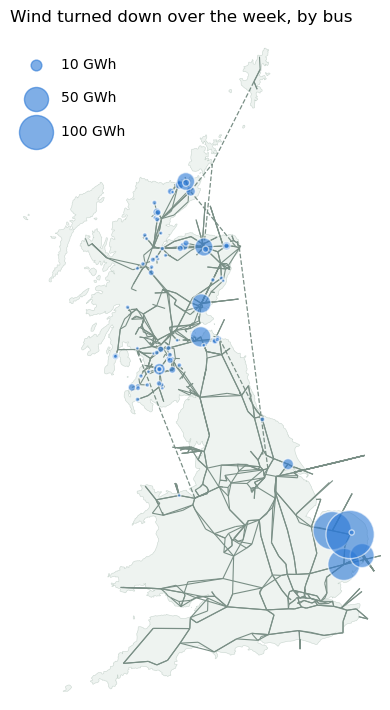

Wind turned down: 845 GWh this week


,GWh turned down
bus,
NORM41,201.0
NECT41,127.0
BRFO41,88.0
LEIS4A,50.0
COCK2-,36.0
TEAL2K,32.0
BLHI4-,28.0
THUS2J,27.0


In [5]:
wind = bm.generators.index[bm.generators.carrier.isin(["wind_onshore", "wind_offshore"])
                           & bm.generators.bus.isin(gb_buses(bm))]
turned_down = (series(s1, "generators", "p", wind) - series(bm, "generators", "p", wind)).clip(lower=0).sum()
by_bus = turned_down.groupby(bm.generators.bus[wind]).sum() / 1e3       # GWh over the week
by_bus = by_bus[by_bus > 1]
buses = bm.buses.loc[by_bus.index]

fig, ax = plt.subplots(figsize=(6.5, 8.5))
network_map(ax, bm, bus_size=0, title="Wind turned down over the week, by bus")
ax.scatter(buses.x, buses.y, s=by_bus * 6, color="#2a78d6", alpha=0.6, edgecolor="white", zorder=4)
for size in (10, 50, 100):
    ax.scatter([], [], s=size * 6, color="#2a78d6", alpha=0.6, label=f"{size} GWh")
ax.legend(loc="upper left", labelspacing=1.4)
plt.show()

print(f"Wind turned down: {turned_down.sum() / 1e3:,.0f} GWh this week")
by_bus.sort_values(ascending=False).head(8).round(0).to_frame("GWh turned down")

Four of the five buses with the most wind turned down are in Norfolk and Suffolk: Norwich Main (NORM41), Necton
(NECT41), Bramford (BRFO41) and Leiston (LEIS4A), where East Anglia's offshore wind lands. That is the power
Norwich-Tilbury and Sea Link would carry towards London. The rest is in Scotland, behind the boundaries to England.

## Interconnectors

In Stage 1 the market schedules trade with neighbouring countries on price alone. When GB exports power its network
cannot deliver to the coast, the balancing mechanism buys the trade back. The gap between the two lines is the
re-traded volume.

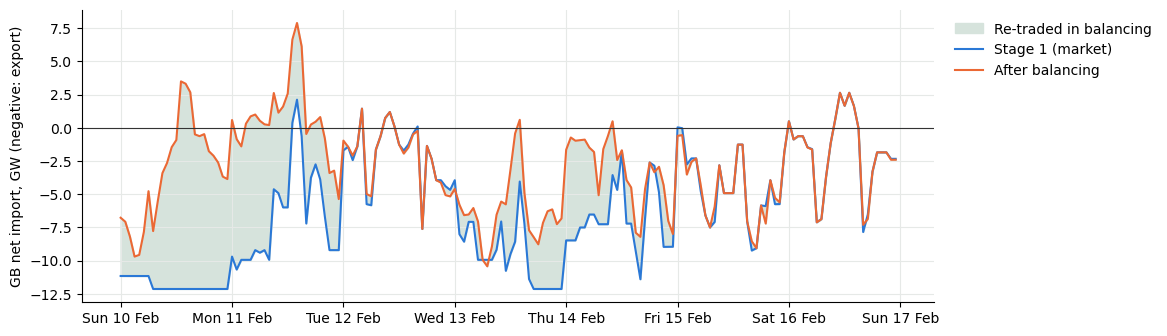

In [6]:
a, b = net_imports(s1) / 1e3, net_imports(bm) / 1e3
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(a.index, a, b, color="#d6e3dc", label="Re-traded in balancing")
ax.plot(a.index, a, color="#2a78d6", lw=1.5, label="Stage 1 (market)")
ax.plot(b.index, b, color="#eb6834", lw=1.5, label="After balancing")
ax.axhline(0, color="#333", lw=0.8)
ax.set_ylabel("GB net import, GW (negative: export)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
day_axis(ax)
plt.show()

In the windy first two days Stage 1 schedules GB to export up to 12 GW. The network cannot carry that much wind to
the coast, so the balancing mechanism cuts exports by up to 10 GW, paying the value of each trade abroad plus a
premium. Later in the week the two lines meet: with less wind, the scheduled trade can be delivered.

## The week in the year

The [CP30 2030 study](../studies/cp30_2030.md) solves all twelve months of 2030 the same way. If you have run it, the
cell below sets this week against February; otherwise it says what to run.

In [7]:
monthly = Path("resources/analysis/CP30_2030_no_acceleration_monthly_metrics.csv")
if monthly.exists():
    mm = pd.read_csv(monthly).set_index("scenario")
    feb = mm.loc["CP30_FFR_2030_Feb_no_acceleration"]
    feb_cost = (feb.ordinary_redispatch_cost_GBP + feb.interconnector_retrading_cost_GBP) / 1e6
    print(f"February 2030, CENTRAL case, as solved: GBP {feb_cost:,.0f} m over {feb.reported_period_hours:.0f} hours; "
          f"this week: GBP {cost['Constraint cost']:,.0f} m over {len(bm.snapshots)} hours")
else:
    print("To compare, run the CENTRAL case's twelve months: add no_acceleration under run_scenarios in "
          "config/config.yaml, then snakemake -j 4 (many hours)")

February 2030, CENTRAL case, as solved: GBP 490 m over 672 hours; this week: GBP 156 m over 168 hours


## Try it yourself

**The recommended network.** Build the same week with Norwich-Tilbury and Sea Link in place (the study's LOWER case),
and compare the cost and the turn-down map:

```yaml
My_CP30_week_lower:
  description: CP30 FFR 2030, 10-16 February, on CP30's recommended network
  inherits: [cp30_ffr_2030_month, market_balancing, network_cp30]
  solve_period: {enabled: true, start: 2030-02-10 00:00, end: 2030-02-16 23:00}
```

**No upgrades after 2025.** Swap `network_cp30` for `network_no_upgrades` (the UPPER case).

**Another week.** Change `solve_period` to a calm week in summer: the network still binds, but far less wind is behind
it, and the cost falls.

The study page has the full-year results, how they compare with NESO's own estimates, and what to bear in mind when
reading them.